# STATE Codex r1 — 03 Training-lineage scarcity

**Run All executes the complete source → input features → released-score metrics → condition-level analysis → curves chain.** The four notebooks share source downloads, but default Run All **recalculates** derived features, released-score errors and all analyses even if computed tables exist. Original public inputs are downloaded if absent and checksum verified before reuse. The separate pipeline CLI offers `--reuse-computed` only for deliberately requested receipt-verified reuse; these notebook defaults do not use it. A cold run requires the documented environment, network access, disk space and CPU time; execute on exxact05 for this reconstruction.

The model outputs are the original released STATE predictions. Recomputing their per-condition full-feature log2-fold-change RMSE requires no new neural inference. Archived five-context means and fitted summaries are comparison targets only; they do not enter the calculations below.

Surviving original methods are preserved byte-for-byte. Continuation methods are reconstructed from the original report and native commands. The declared bootstrap seed, axis-standardization population and quintile-matching implementation are recorded explicitly; they were not selected by fitting the historical answers. See [method details](../methods/METHODS.md), [source manifest](../methods/sources.json), [pipeline](../methods/run_pipeline.py), and [original report](../recovery/original_handoff/REPORT.md).

## 1. Data acquisition

The feature sources are the original training-context map and DepMap 23Q4 lineage labels. The outcome source is official ST-SE `eval_last`; ST-HVG discovery rows provide the separate direction check. This reconstructs the actual published output analysis without new model inference.

In [1]:
from pathlib import Path
import importlib.util, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, JSON
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'methods/sources.json').is_file())
spec=importlib.util.spec_from_file_location('state_notebook_workflow',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
INPUTS=ROOT/'inputs'
FEATURES=ROOT/'computed/features'
ANALYSIS=ROOT/'computed/analysis'
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)
source_manifest=json.loads((ROOT/'methods/sources.json').read_text())
source_rows=pd.DataFrame(source_manifest['inputs']).drop_duplicates('path')
display(source_rows[['path','bytes','sha256','url']])
print('Unique public source files:',len(source_rows))
print('Declared source bytes:',int(source_rows.bytes.sum()))
print('Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.')


,path,bytes,sha256,url
0,acquisition/DepMap_Model_23Q4.csv,530469,6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341,https://ndownloader.figshare.com/files/43746708
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,449782440,d8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8,https://ndownloader.figshare.com/files/43347204
2,acquisition/cmp_rnaseq_all_20220624.zip,940707972,2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a,https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip
3,acquisition/tahoe_obs_metadata.parquet,2293981573,e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe,https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b00654...
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,517889,44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
5,acquisition/official_scores_st_se/C32_pred_de.csv,388384053,7169a2f135657b9f1db7440a9c7feef3f759428b0783f4fc89ac1c48ccac4d76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
6,acquisition/official_scores_st_se/C32_results.csv,468674,cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
7,acquisition/official_scores_st_se/C32_agg_results.csv,3547,5a88c0744b9d31bfa73dcbcbe2d3366b7779f3e334d3a74be0bc7d6a8a53ca76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
8,acquisition/official_scores/C32_real_de.csv,387383572,19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
9,acquisition/official_scores_st_se/HOP62_pred_de.csv,393288407,5db83d0ef3c96cbcfc9f61dd1e851e5e4f2661a22fe831638e80741036ecc594,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...


Unique public source files: 55
Declared source bytes: 11545305551
Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.


## 2. Processing

Training contexts are mapped from the original source metadata and counted within each held-out context’s DepMap lineage. The counts are calculated from membership, not copied from reported numbers. The code then applies `−log(1 + count)`.

In [2]:
# Actual source acquisition / verification, input processing, released-score reduction,
# condition-level regressions and curves, even when derived outputs already exist.
wf.run_pipeline(ROOT)
wf.show_receipts(ROOT)
wf.source_functions(ROOT,'methods/build_features.py',['build_expression'])
mapping=wf.read_csv(ROOT,'computed/features/cell_line_mapping.csv')
lineage=wf.read_csv(ROOT,'computed/features/lineage_features.csv')
display(mapping[['cell_line','lineage']]);display(lineage)


Recalculating source → features → released-score metrics → analysis. Existing source downloads are checksum verified before reuse.
Running download_inputs.py
{"event": "start", "files": 55, "bytes": 11545305551, "destination": "/ewsc/yektefai/spectra_runs/state_codex_r1_reconstruction_20261109/inputs"}


{"event": "verified", "completed": 1, "path": "acquisition/DepMap_Model_23Q4.csv", "bytes": 530469}
{"event": "verified", "completed": 2, "path": "acquisition/state_tahoe_cell_type_onehot_map_verified.pkl", "bytes": 517889}


{"event": "verified", "completed": 3, "path": "acquisition/official_scores_st_se/C32_pred_de.csv", "bytes": 388384053}
{"event": "verified", "completed": 4, "path": "acquisition/official_scores_st_se/C32_results.csv", "bytes": 468674}
{"event": "verified", "completed": 5, "path": "acquisition/official_scores_st_se/C32_agg_results.csv", "bytes": 3547}
{"event": "verified", "completed": 6, "path": "acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv", "bytes": 449782440}


{"event": "verified", "completed": 7, "path": "acquisition/official_scores/C32_real_de.csv", "bytes": 387383572}
{"event": "verified", "completed": 8, "path": "acquisition/official_scores_st_se/HOP62_results.csv", "bytes": 463111}
{"event": "verified", "completed": 9, "path": "acquisition/official_scores_st_se/HOP62_agg_results.csv", "bytes": 3526}
{"event": "verified", "completed": 10, "path": "acquisition/official_scores_st_se/HOP62_pred_de.csv", "bytes": 393288407}


{"event": "verified", "completed": 11, "path": "acquisition/official_scores_st_se/HepG2-C3A_pred_de.csv", "bytes": 385102563}
{"event": "verified", "completed": 12, "path": "acquisition/official_scores/HOP62_real_de.csv", "bytes": 395844167}
{"event": "verified", "completed": 13, "path": "acquisition/official_scores_st_se/HepG2-C3A_results.csv", "bytes": 473841}
{"event": "verified", "completed": 14, "path": "acquisition/official_scores_st_se/HepG2-C3A_agg_results.csv", "bytes": 3591}


{"event": "verified", "completed": 15, "path": "acquisition/official_scores_st_se/Hs 766T_pred_de.csv", "bytes": 390361943}
{"event": "verified", "completed": 16, "path": "acquisition/official_scores_st_se/Hs 766T_results.csv", "bytes": 468068}
{"event": "verified", "completed": 17, "path": "acquisition/official_scores_st_se/Hs 766T_agg_results.csv", "bytes": 3534}
{"event": "verified", "completed": 18, "path": "acquisition/official_scores/HepG2-C3A_real_de.csv", "bytes": 381547673}


... (43 outputs left out)

**Executed helper:** `methods/build_features.py::build_expression`

def build_expression(root, inputs, out):
    archive=inputs/'acquisition/cmp_rnaseq_all_20220624.zip'
    original=root/'methods/original/01_build_prospective_axis.py'
    # This exact archive member was used in native command 377, then command 521.
    member='rnaseq_tpm_20220624.csv'
    with tempfile.TemporaryDirectory(prefix='cmp-stage-',dir=out) as temp:
        extracted=Path(temp)/member
        with zipfile.ZipFile(archive) as z:
            if member not in z.namelist():
                raise ValueError(f'Original CMP member missing: {member}')
            with z.open(member) as src,extracted.open('wb') as dst:
                shutil.copyfileobj(src,dst,8*1024*1024)
        extracted_meta={'member':member,'bytes':extracted.stat().st_size,'sha256':digest(extracted)}
        cmd=[sys.executable,str(original),'--cell-map',str(inputs/EXPRESSION[3]),
             '--sample-info',str(inputs/EXPRESSION[0]),'--ccle-expression',str(inputs/EXPRESSION[1]),
             '--cmp-expression',str(extracted),'--output-dir',str(out),'--n-genes','2000','--k-neighbors','5']
        print('Running unchanged original CMP/CCLE feature builder',flush=True)
        result=subprocess.run(cmd,text=True,capture_output=True)
        (out/'original_axis_stdout.txt').write_text(result.stdout)
        (out/'original_axis_stderr.txt').write_text(result.stderr)
        if result.returncode:
            raise RuntimeError(f'Original axis builder failed ({result.returncode}): {result.stderr[-6000:]}')
        print(result.stdout,flush=True)
    mapping=pd.read_csv(out/'cell_line_mapping.csv')
    train=mapping[(~mapping.held_out)&mapping.depmap_id.notna()]
    held=mapping[mapping.held_out].copy()
    lineage_counts=train.groupby('lineage',dropna=False).size()
    held['n_training_contexts']=held.lineage.map(lineage_counts).fillna(0).astype(int)
    held['axis_value']=-np.log1p(held.n_training_contexts)
    held['axis_level']=held.axis_value.rank(method='dense').astype(int)
    lineage=held[['cell_line','lineage','n_training_contexts','axis_value','axis_level']].sort_values(['axis_value','cell_line'])
    lineage.to_csv(out/'lineage_features.csv',index=False)
    primary=pd.read_csv(out/'primary_cmp_distances.csv')
    independent=pd.read_csv(out/'independent_ccle_distances.csv')
    checks={'cmp_extracted_member':extracted_meta,'lineage_rule':'Count mapped non-held-out training contexts by DepMap Oncotree lineage; -log1p(count), tied values retain same dense level',
            'training_mapped_contexts':len(train),'all_original_feature_comparisons_passed':True}
    old,prov=expected_table(root,'spc_table.csv')
    if old is not None:
        checks['primary_vs_original_max_abs_error']=compare_values(primary,old,[('distance','distance')],1e-10)
        checks['ccle_vs_original_max_abs_error']=compare_values(independent,old,[('distance','ccle_distance')],1e-10)
        checks['distance_original_comparison_source']=prov
    old_lineage,lp=expected_table(root,'lineage_followup/spc_table.csv')
    if old_lineage is not None:
        checks['lineage_vs_original_max_abs_error']=compare_values(lineage,old_lineage,[('axis_value','axis_value')],1e-12)
        checks['lineage_original_comparison_source']=lp
    files=['cell_line_mapping.csv','primary_cmp_distances.csv','primary_cmp_pairwise_distances.csv','primary_gene_set.txt',
           'independent_ccle_distances.csv','independent_ccle_pairwise_distances.csv','axis_replication_summary.json',
           'lineage_features.csv','original_axis_stdout.txt','original_axis_stderr.txt']
    return files,checks

,cell_line,lineage
0,A-172,CNS/Brain
1,A-427,Lung
2,A498,Kidney
3,A549,Lung
4,AN3 CA,Uterus
5,AsPC-1,Pancreas
6,BT-474,Breast
7,C-33 A,Cervix
8,C32,Skin
9,CFPAC-1,Pancreas


,cell_line,lineage,n_training_contexts,axis_value,axis_level
0,HOP62,Lung,14,-2.708050,1
1,Hs 766T,Pancreas,4,-1.609438,2
2,PANC-1,Pancreas,4,-1.609438,2
3,C32,Skin,3,-1.386294,3
4,HepG2/C3A,Liver,1,-0.693147,4


## 3. Axis

Increasing lineage scarcity means fewer mapped training contexts in the same lineage. The feature is built before its join to `eval_last` score measurements. The two pancreatic contexts share one feature value; the tie is preserved.

In [3]:
AXIS='lineage'
conditions=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/per_condition_scores.csv')
axis=conditions[['cell_line','axis_value','distance_z']].drop_duplicates().sort_values('axis_value')
assert axis.cell_line.is_unique
display(axis)


,cell_line,axis_value,distance_z
1136,HOP62,-2.708050,-1.709125
3408,Hs 766T,-1.609438,-0.012610
4544,PANC-1,-1.609438,-0.012610
0,C32,-1.386294,0.331976
2272,HepG2/C3A,-0.693147,1.402358


## 4. Levels and eligibility

Dense ranks define four distinct scarcity levels across the five held-out contexts. The same compound hashing and eligibility rules govern discovery and confirmation; the context shape uses five means with the pancreatic tie rather than pooling to four lineage means.

In [4]:
levels=axis.copy();levels['level']=levels.axis_value.rank(method='dense').astype(int);display(levels)
eligibility=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/compound_eligibility.csv')
display(eligibility.head(12));wf.show_conditions(conditions)


,cell_line,axis_value,distance_z,level
1136,HOP62,-2.708050,-1.709125,1
3408,Hs 766T,-1.609438,-0.012610,2
4544,PANC-1,-1.609438,-0.012610,2
0,C32,-1.386294,0.331976,3
2272,HepG2/C3A,-0.693147,1.402358,4


,compound,n_contexts,n_doses,n_targets,partition
0,18glycyrrhetinicacid,5,3,3,discovery
1,4egi1,5,3,3,discovery
2,5azacytidine,5,3,3,confirmation
3,5fluorouracil,5,3,3,confirmation
4,8hydroxyquinoline,5,3,3,confirmation
5,9ing41,5,3,3,confirmation
6,abemaciclib,5,3,3,discovery
7,abirateroneacetate,5,3,3,confirmation
8,acetazolamide,5,3,3,discovery
9,acetohexamide,5,3,3,discovery


,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,-1.386294,2.746371,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,-1.386294,3.344171,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,-1.386294,2.687589,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,-1.386294,3.276504,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,-1.386294,3.041923,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,-1.386294,3.500859,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,-1.386294,3.283515,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,-1.386294,3.117587,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,-1.386294,2.678597,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,-1.386294,2.881910,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 5. Model / released scores

Recompute original full-feature STATE and identity-reference LFC RMSE from the `eval_last` released rows. Condition-level DE and observed-cell measurements enter the adjustment; no archived adjusted estimate is supplied to the fitter.

In [5]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['compute_lfc_scores'])
wf.show_conditions(conditions)


**Executed helper:** `methods/original/04_analyze_frozen_axis.py::compute_lfc_scores`

def compute_lfc_scores(real_path: Path, pred_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    use_real = ["target", "feature", "fold_change", "fdr"]
    use_pred = ["target", "feature", "fold_change"]
    real_iter = pd.read_csv(real_path, usecols=use_real, chunksize=chunksize)
    pred_iter = pd.read_csv(pred_path, usecols=use_pred, chunksize=chunksize)
    accum: dict[str, list[float]] = {}
    total_rows = 0
    for real, pred in zip(real_iter, pred_iter, strict=True):
        if len(real) != len(pred):
            raise RuntimeError("real/pred DE chunk length mismatch")
        if not np.array_equal(real["target"].to_numpy(), pred["target"].to_numpy()):
            raise RuntimeError("real/pred DE target order mismatch")
        if not np.array_equal(real["feature"].to_numpy(), pred["feature"].to_numpy()):
            raise RuntimeError("real/pred DE feature order mismatch")
        real_lfc = np.log2(real["fold_change"].to_numpy(dtype=float))
        pred_lfc = np.log2(pred["fold_change"].to_numpy(dtype=float))
        if not (np.isfinite(real_lfc).all() and np.isfinite(pred_lfc).all()):
            raise RuntimeError("non-finite released fold change encountered")
        temp = pd.DataFrame(
            {
                "target": real["target"].to_numpy(),
                "state_sq": (pred_lfc - real_lfc) ** 2,
                "identity_sq": real_lfc**2,
                "is_de": real["fdr"].to_numpy(dtype=float) < 0.05,
                "n": 1,
            }
        )
        grouped = temp.groupby("target", sort=False).agg(
            state_sse=("state_sq", "sum"),
            identity_sse=("identity_sq", "sum"),
            n_de=("is_de", "sum"),
            n_genes=("n", "sum"),
        )
        for target, row in grouped.iterrows():
            current = accum.setdefault(target, [0.0, 0.0, 0.0, 0.0])
            current[0] += float(row["state_sse"])
            current[1] += float(row["identity_sse"])
            current[2] += float(row["n_de"])
            current[3] += float(row["n_genes"])
        total_rows += len(real)
    result = pd.DataFrame(
        [
            {
                "target": target,
                "state_lfc_rmse": math.sqrt(values[0] / values[3]),
                "identity_lfc_rmse": math.sqrt(values[1] / values[3]),
                "n_de": int(values[2]),
                "n_genes_lfc": int(values[3]),
            }
            for target, values in accum.items()
        ]
    )
    if int(result["n_genes_lfc"].sum()) != total_rows:
        raise RuntimeError("DE row accounting mismatch")
    return result

,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,-1.386294,2.746371,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,-1.386294,3.344171,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,-1.386294,2.687589,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,-1.386294,3.276504,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,-1.386294,3.041923,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,-1.386294,3.500859,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,-1.386294,3.283515,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,-1.386294,3.117587,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,-1.386294,2.678597,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,-1.386294,2.881910,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 6. Regressions, curves and controls

The curve, clustered fits, paired reference comparison and compound-bootstrap intervals are calculated from the rebuilt condition table. Dose-specific and leave-context fits expose the original instability checks, while the separate ST-HVG discovery calculation tests the historical direction disagreement.

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::within_design`

def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::fit_within`

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::context_spc`

def context_spc(frame: pd.DataFrame, reps: int, seed: int) -> pd.DataFrame:
    compound_context = frame.groupby(["compound", "cell_line"], as_index=False).agg(
        state_lfc_rmse=("state_lfc_rmse", "mean"),
        identity_lfc_rmse=("identity_lfc_rmse", "mean"),
        distance=("distance", "first"),
        ccle_distance=("ccle_distance", "first"),
        n_conditions=("target", "nunique"),
    )
    compounds = sorted(compound_context["compound"].unique())
    rng = np.random.default_rng(seed)
    rows = []
    for cell, group in compound_context.groupby("cell_line"):
        indexed = group.set_index("compound")
        state_values = indexed.loc[compounds, "state_lfc_rmse"].to_numpy()
        reference_values = indexed.loc[compounds, "identity_lfc_rmse"].to_numpy()
        state_boot = np.empty(reps)
        reference_boot = np.empty(reps)
        for i in range(reps):
            sample = rng.integers(0, len(compounds), len(compounds))
            state_boot[i] = state_values[sample].mean()
            reference_boot[i] = reference_values[sample].mean()
        rows.append(
            {
                "cell_line": cell,
                "distance": group["distance"].iloc[0],
                "ccle_distance": group["ccle_distance"].iloc[0],
                "n_compounds": len(compounds),
                "n_conditions": int(group["n_conditions"].sum()),
                "state_rmse_mean": state_values.mean(),
                "state_rmse_ci_low": np.quantile(state_boot, 0.025),
                "state_rmse_ci_high": np.quantile(state_boot, 0.975),
                "identity_rmse_mean": reference_values.mean(),
                "identity_rmse_ci_low": np.quantile(reference_boot, 0.025),
                "identity_rmse_ci_high": np.quantile(reference_boot, 0.975),
            }
        )
    return pd.DataFrame(rows).sort_values("distance")

... (5 outputs left out)

,recomputed_diagnostic
state_raw_positive,True
state_adjusted_positive,True
context_order_rho_at_least_point70,True
all_dose_adjusted_positive,True
all_leave_one_context_out_adjusted_positive,False


Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95,status,reconstructed_method,method,cutpoint_scope
0,models / state_raw,0.138244,0.003503,0.000000e+00,0.000000e+00,4020.0,804.0,268.0,[],"[0.13151643594925108, 0.14495319754753258]",NaN,NaN,NaN,NaN,NaN
1,models / state_adjusted,0.032226,0.005004,5.948682e-11,1.189736e-10,4020.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[0.022425278603436502, 0.0417230963849279]",NaN,NaN,NaN,NaN,NaN
2,models / identity_raw,0.125582,0.003053,0.000000e+00,0.000000e+00,4020.0,804.0,268.0,[],"[0.11973696060867156, 0.13154727895042664]",NaN,NaN,NaN,NaN,NaN
3,paired_state_minus_identity,0.012662,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[0.0028347401297653513, 0.022362027798700463]",NaN,NaN,NaN,NaN
4,dose_sensitivity / 0.05,0.036204,0.005674,8.843584e-11,1.768717e-10,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
5,dose_sensitivity / 0.5,0.049040,0.006621,6.488223e-14,1.297645e-13,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
6,dose_sensitivity / 5.0,0.010265,0.007401,8.272587e-02,1.654517e-01,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
7,leave_one_context_out / C32,0.039493,0.007105,1.362808e-08,2.725617e-08,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
8,leave_one_context_out / HOP62,0.119546,0.011456,8.551698e-26,1.710340e-25,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
9,leave_one_context_out / HepG2/C3A,-0.011958,0.004418,9.966056e-01,6.788723e-03,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN


,cell_line,distance,ccle_distance,n_compounds,n_conditions,state_rmse_mean,state_rmse_ci_low,state_rmse_ci_high,identity_rmse_mean,identity_rmse_ci_low,identity_rmse_ci_high
0,HOP62,-2.708050,NaN,268,804,2.980762,2.954566,3.006719,1.680951,1.655997,1.706377
1,Hs 766T,-1.609438,NaN,268,804,3.180017,3.146924,3.214407,1.821537,1.781326,1.863767
2,PANC-1,-1.609438,NaN,268,804,2.790114,2.765981,2.815020,1.553926,1.526577,1.581677
3,C32,-1.386294,NaN,268,804,3.227563,3.195315,3.260231,1.961917,1.933713,1.989548
4,HepG2/C3A,-0.693147,NaN,268,804,3.415138,3.392556,3.438464,2.062156,2.030132,2.094043


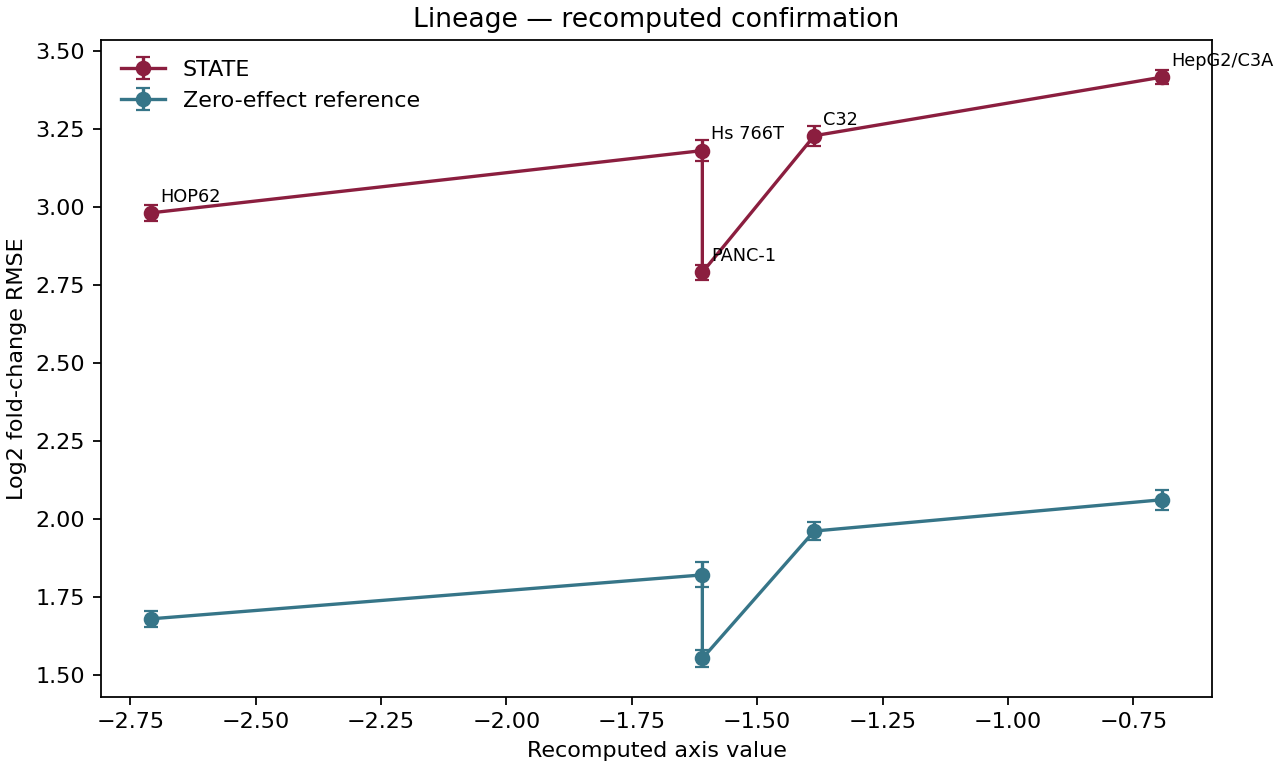

,effect_quintile,cell_count_quintile,C32,HOP62,HepG2/C3A,Hs 766T,PANC-1
0,0,2,0,0,0,0,1
1,0,3,6,24,20,19,60
2,0,4,37,171,19,149,298
3,1,1,0,0,1,0,0
4,1,2,8,27,42,42,46
5,1,3,80,160,36,102,151
6,1,4,12,47,0,15,35
7,2,0,0,0,2,0,0
8,2,1,9,21,71,40,26
9,2,2,153,130,46,88,74


Matching rows: 4020 — inspect full assignment/weights in the linked CSV.


,target,overlap_at_N,overlap_at_50,overlap_at_100,overlap_at_200,overlap_at_500,precision_at_N,precision_at_50,precision_at_100,precision_at_200,...,effect_quintile,cell_count_quintile,effect_q_1,effect_q_2,effect_q_3,effect_q_4,cells_q_1,cells_q_2,cells_q_3,cells_q_4
0,"[('(S)-Crizotinib', 0.05, 'uM')]",0.096958,0.00,0.01,0.025,0.086000,0.325355,0.00,0.01,0.025,...,3,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,"[('(S)-Crizotinib', 0.5, 'uM')]",0.018182,0.00,0.04,0.020,0.018182,0.133659,0.00,0.04,0.020,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,"[('(S)-Crizotinib', 5.0, 'uM')]",0.024735,0.02,0.01,0.030,0.024735,0.176471,0.02,0.01,0.030,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,"[('5-Azacytidine', 0.05, 'uM')]",0.033520,0.00,0.00,0.005,0.033520,0.214131,0.00,0.00,0.005,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,"[('5-Azacytidine', 0.5, 'uM')]",0.048165,0.02,0.01,0.015,0.048165,0.257746,0.02,0.01,0.015,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5,"[('5-Azacytidine', 5.0, 'uM')]",0.060773,0.00,0.05,0.045,0.060773,0.216006,0.00,0.05,0.045,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
6,"[('5-Fluorouracil', 0.05, 'uM')]",0.028037,0.02,0.02,0.025,0.028037,0.190166,0.02,0.02,0.025,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
7,"[('5-Fluorouracil', 0.5, 'uM')]",0.031111,0.00,0.00,0.010,0.031111,0.264360,0.00,0.00,0.010,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
8,"[('5-Fluorouracil', 5.0, 'uM')]",0.063014,0.02,0.04,0.070,0.063014,0.207224,0.02,0.04,0.070,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
9,"[('8-Hydroxyquinoline', 0.05, 'uM')]",0.069204,0.00,0.00,0.070,0.069204,0.179910,0.00,0.00,0.070,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


**ST-HVG discovery direction on the lineage axis**

,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,-0.022861,0.005233,9.999938e-01,1.249928e-05,1660.0,332.0,111.0,[],"[-0.03336153430734956, -0.012946371167150148]",NaN
1,models / state_adjusted,-0.072321,0.006344,1.000000e+00,4.180361e-30,1660.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.08442752892004884, -0.059791183474496114]",NaN
2,models / identity_raw,0.120531,0.004352,3.675002e-169,7.350005e-169,1660.0,332.0,111.0,[],"[0.11202177977982747, 0.12899888948090096]",NaN
3,paired_state_minus_identity,-0.143392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.15038231222746684, -0.13634314395601613]"
4,dose_sensitivity / 0.05,-0.063487,0.008966,1.000000e+00,1.433549e-12,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,-0.078939,0.008382,1.000000e+00,4.596435e-21,550.0,110.0,110.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,-0.072450,0.010206,1.000000e+00,1.256016e-12,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,-0.032969,0.009307,9.998016e-01,3.967836e-04,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,-0.326820,0.013031,1.000000e+00,8.197860e-139,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / HepG2/C3A,-0.011449,0.007160,9.450728e-01,1.098545e-01,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,-0.022861,0.005233,9.999938e-01,1.249928e-05,1660.0,332.0,111.0,[],"[-0.03336153430734956, -0.012946371167150148]",NaN
1,models / state_adjusted,-0.072321,0.006344,1.000000e+00,4.180361e-30,1660.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.08442752892004884, -0.059791183474496114]",NaN
2,models / identity_raw,0.120531,0.004352,3.675002e-169,7.350005e-169,1660.0,332.0,111.0,[],"[0.11202177977982747, 0.12899888948090096]",NaN
3,paired_state_minus_identity,-0.143392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.15038231222746684, -0.13634314395601613]"
4,dose_sensitivity / 0.05,-0.063487,0.008966,1.000000e+00,1.433549e-12,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,-0.078939,0.008382,1.000000e+00,4.596435e-21,550.0,110.0,110.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,-0.072450,0.010206,1.000000e+00,1.256016e-12,555.0,111.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,-0.032969,0.009307,9.998016e-01,3.967836e-04,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,-0.326820,0.013031,1.000000e+00,8.197860e-139,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / HepG2/C3A,-0.011449,0.007160,9.450728e-01,1.098545e-01,1328.0,332.0,111.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


In [6]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['within_design','fit_within','context_spc'])
wf.source_functions(ROOT,'methods/reconstruct.py',['bootstrap_slopes_fast','quintile_matching'])
analysis=wf.read_json(ROOT,f'computed/analysis/{AXIS}/analysis.json')
display(JSON(analysis['policy']))
display(pd.Series(analysis['computed_diagnostics'],name='recomputed_diagnostic').to_frame())
print('Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.')
fits=wf.show_fits(analysis['partitions']['confirmation'])
curve=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/spc_table.csv')
display(curve)
wf.show_curve(ROOT,AXIS)
strata=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_strata.csv')
weights=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_weights.csv')
display(strata)
print('Matching rows:',len(weights),'— inspect full assignment/weights in the linked CSV.')
display(weights.head(10))
display(Markdown('**ST-HVG discovery direction on the lineage axis**'))
wf.show_fits(wf.read_json(ROOT,f'computed/analysis/{AXIS}/hvg_discovery_analysis.json'))


## 7. Historical result and decision

The original agent rejected this follow-up after the 5 µM estimate weakened, removing HepG2/C3A reversed the adjusted direction, and ST-HVG discovery disagreed. Its related-checkpoint timing is a historical qualification, not something inferred from these numerical results. Rebuilt values and differences are shown explicitly.

In [7]:
comparison=wf.historical_comparison(ROOT,'lineage')
wf.original_decision(ROOT,'training_lineage_scarcity','Historical finding: favorable overall slope and shape, but dose/context instability and opposite discovery direction. Exact operationalization also followed access to the related eval_best checkpoint. The newly computed sensitivities above permit direct comparison with those recorded grounds.')


,axis,metric,historical,recomputed,difference,tolerance,within_tolerance,note
18,lineage,state_adjusted,0.032230,0.032226,-4.007121e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
19,lineage,paired_state_minus_identity,0.012660,0.012662,1.652471e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
20,lineage,context_spearman,0.820780,0.820783,2.681668e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
21,lineage,confirmation_rows,4020.000000,4020.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
22,lineage,confirmation_targets,804.000000,804.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
23,lineage,confirmation_compounds,268.000000,268.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
24,lineage,confirmation_contexts,5.000000,5.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
27,lineage,hvg_discovery_adjusted,-0.072330,-0.072321,8.550385e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
28,lineage,exclude_HepG2_adjusted,-0.011960,-0.011958,1.543879e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
29,lineage,dose_5_adjusted,0.010270,0.010265,-4.702336e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.


Historical values are validation targets only. Differences are reported rather than used to tune inputs or calculations.


**Original decision:** `axis_negative_unstable_and_not_independently_prospective`

Historical finding: favorable overall slope and shape, but dose/context instability and opposite discovery direction. Exact operationalization also followed access to the related eval_best checkpoint. The newly computed sensitivities above permit direct comparison with those recorded grounds.

Historical overall disposition: CLOSED_NEGATIVE_NO_CERTIFIED_GENERALIZABILITY_FAILURE
This records the original agent determination; it does not create a new scientific certification.
